In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

In [2]:
from matplotlib import rc
rc('text', usetex=True)
rc('font', family='serif')
rc('font', serif='times')
#rc('font', weight='bolder')
rc('mathtext', default='sf')
rc("lines", markeredgewidth=1)
rc("lines", linewidth=1)
rc('axes', labelsize=20) #24
rc("axes", linewidth=0.5) #2)
rc('xtick', labelsize=10)
rc('ytick', labelsize=10)
rc('legend', fontsize=10) #16
rc('ytick', right='True',direction= 'in')
rc('xtick', top='True',direction= 'in')
rc('xtick.major', pad=15) #8)
rc('ytick.major', pad=15) #8)
rc('xtick.major', size=12) #8)
rc('ytick.major', size=12) #8)
rc('xtick.minor', size=7) #8)
rc('ytick.minor', size=7) #8)

def set_tick_sizes(ax, major, minor):
    for l in ax.get_xticklines() + ax.get_yticklines():
        l.set_markersize(major)
    for tick in ax.xaxis.get_minor_ticks() + ax.yaxis.get_minor_ticks():
        tick.tick1line.set_markersize(minor)
        tick.tick2line.set_markersize(minor)
    ax.xaxis.LABELPAD=10.
    ax.xaxis.OFFSETTEXTPAD=10.

In [3]:
%matplotlib inline

import gwmat
import numpy as np
from gwmat import point_lens
import matplotlib.pyplot as plt
from pycbc.types import FrequencySeries
from pycbc.waveform import get_fd_waveform

mass1, mass2 = 50, 50
# Generating FD waveform
hp, hc = get_fd_waveform(approximant = 'IMRPhenomPv3HM',
                            mass1 = mass1, mass2 = mass2,
                            f_lower = 10, delta_f = 1.0/4)

The amplification factor for a point mass lens in wave optics limit is given by:

$$
    F(\omega, y) = \exp{\left\{ \frac{\pi \omega}{4} + \frac{i \omega}{2} \left[ \ln{\left( \frac{\omega}{2} \right) - 2 \phi_m (y)} \right] \right\}} \times \Gamma{\left( 1 - \frac{i \omega}{2} \right)} {}_1F_1 \left( \frac{i \omega}{2}, 1, \frac{i \omega y^2}{2} \right)
$$

$\omega \to $ dimensionless frequency which depends solely on the redshifted lens mass, $M_{L_{Z}}$ for a given dimensionful frquency $f$ and $$\omega = \frac{8 \pi G M_{L_{Z}} f}{c^3} $$

$$
    \phi_m(y) = \frac{(x_m - y)^2}{2} - \ln{(x_m)}
$$

$$
    x_m = (y + \sqrt{y^2 + 4}) / 2
$$

$$
{}_1F_1 \to \text{ Confluent hypergeometric function of 1st kind}
$$

$$
    \xi_0 \to \text{ Einstein radius of point mass lens}
$$

In [4]:
# import numpy as np
# from scipy.special import gamma
# import mpmath

# # Constants
# G = 6.67430e-11  # gravitational constant in m^3 kg^-1 s^-2
# c = 3e8    # speed of light in m/s

# def phi_m(y):
#     x_m = (y + np.sqrt(y**2 + 4)) / 2
#     return (x_m - y)**2 / 2 - np.log(x_m)

# def F(Mlz, y, f):
#     omega = (8 * np.pi * G * Mlz * 1e30 * f) / c**3
    
#     # Exponential term
#     exp_term = np.exp(np.pi * omega / 4 + (1j * omega / 2) * (np.log(max(omega / 2, 1e-10)) - 2 * phi_m(y)))
    
#     # Gamma function term
#     gamma_term = gamma(1 - 1j * omega / 2)
    
#     # Confluent hypergeometric function term
#     hyp1f1_term = mpmath.hyp1f1(1j * omega / 2, 1, 1j * omega * y**2 / 2)
    
#     return exp_term * gamma_term * hyp1f1_term

# freq = hp.sample_frequencies
# Mlz = [10,1e2,1e3]    # Lens mass (in Solar mass)
# y = 0.1       # Impact parameter

# result = np.empty((3, len(freq)), dtype=complex)

# for mass in range(len(Mlz)):
#     for frequency in range(len(freq)):
#         Ampl = complex(F(Mlz[mass], y, freq[frequency]))
#         result[mass, frequency] = Ampl

In [5]:
freq = hp.sample_frequencies
Mlz = [10,1e2,1e3]
y = 0.8

hp_lensed = {}
t_delay = {}

for i in range(len(Mlz)):
    Ffs = [gwmat.cythonized_point_lens.Ff_effective(f, ml=Mlz[i], y=y) for f in freq]
    t_delay[i] = point_lens.time_delay(ml=Mlz[i], y=y)

    hp_lensed[i] = FrequencySeries(np.conj(Ffs) * hp.numpy(), delta_f=hp.delta_f)#.cyclic_time_shift(-(t_delay[i] - 0.1))

## We will plot the squared norm of the Fourier components of the lensed and unlesned signal for different values of lens mass

In [6]:
color = ["orange", "green", "red"]

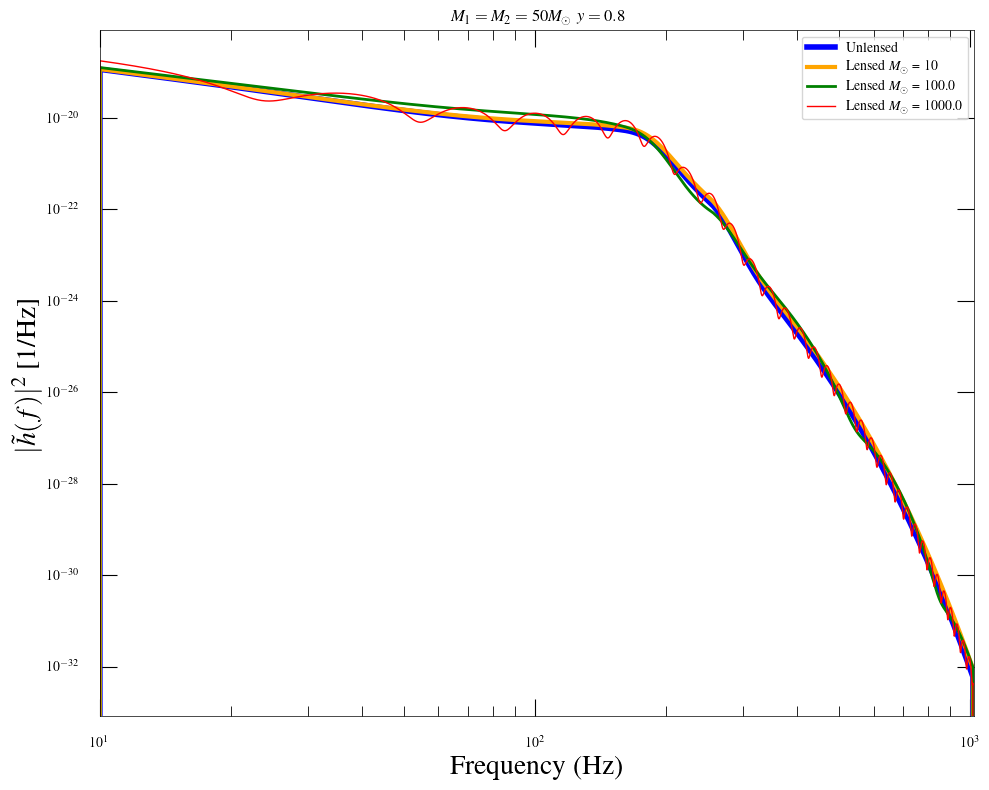

In [7]:
num_curves = len(Mlz)

linewidths = np.linspace(3, 1, num_curves)

plt.figure(figsize=(10, 8))
plt.title(rf'$M_1 = M_2 = {mass1} M_\odot$ $y = 0.8$')

plt.loglog(hp.sample_frequencies, np.sqrt(hp.squared_norm()), label='Unlensed', color='blue', linewidth=4)

for i in range(num_curves):
    plt.loglog(hp_lensed[i].sample_frequencies, np.sqrt(hp_lensed[i].squared_norm()),
               label=fr'Lensed $M_\odot$ = {Mlz[i]}',
               color=color[i],
               linewidth=linewidths[i])

plt.xlabel(r"Frequency (Hz)")
plt.ylabel(r'$|\tilde{h}(f)|^2$ [1/Hz]')
plt.xlim(10, 1024)
# plt.ylim(1e-56, 1e-38)
plt.legend()

ax = plt.gca()
set_tick_sizes(ax, major=12, minor=7)
plt.tight_layout()
plt.show()


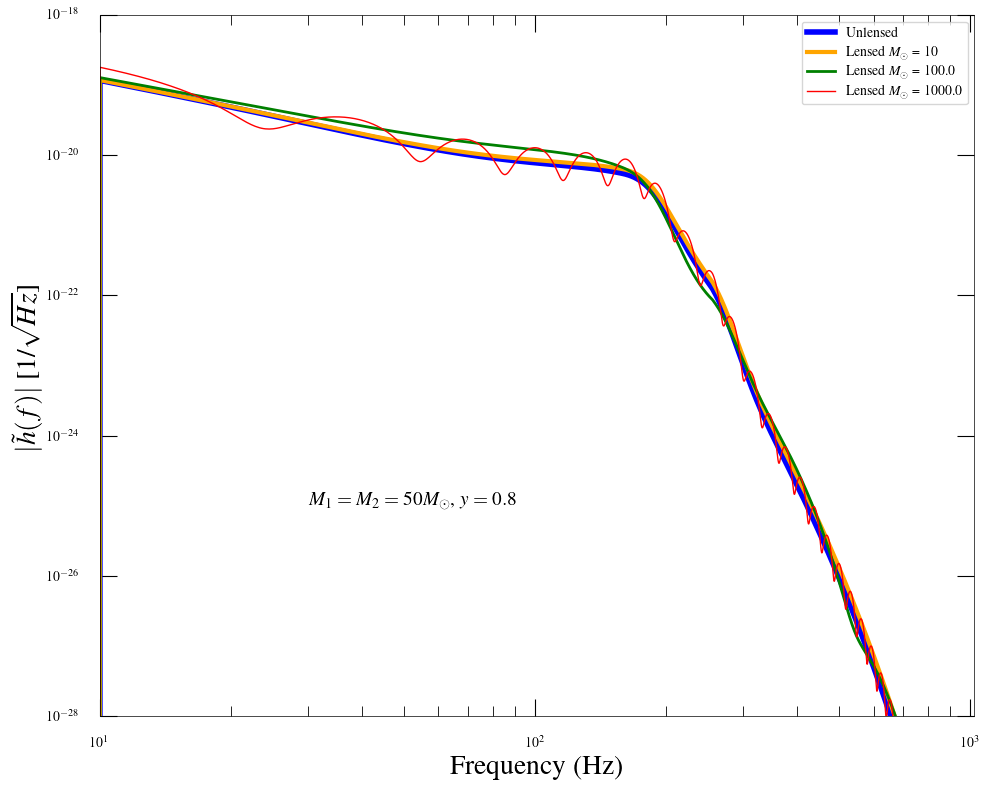

In [8]:
num_curves = len(Mlz)
linewidths = np.linspace(3, 1, num_curves)

plt.figure(figsize=(10, 8))

# Plot curves
plt.loglog(hp.sample_frequencies, np.sqrt(hp.squared_norm()), label='Unlensed', color='blue', linewidth=4)

for i in range(num_curves):
    plt.loglog(hp_lensed[i].sample_frequencies, np.sqrt(hp_lensed[i].squared_norm()),
               label=fr'Lensed $M_\odot$ = {Mlz[i]}',
               color=color[i],
               linewidth=linewidths[i])

# Axes labels and limits
plt.xlabel(r"Frequency (Hz)")
plt.ylabel(r'$|\tilde{h}(f)|$ [1/$\sqrt{Hz}$]')
plt.xlim(10, 1024)
plt.ylim(1e-28, 1e-18)
plt.legend()

# Insert the text *inside* the plot at a relative position
# Use log scale coordinates
ax = plt.gca()
ax.text(30, 1e-25, rf'$M_1 = M_2 = {mass1} M_\odot$, $y = 0.8$', fontsize=14)

# Optional: Add tick styling
set_tick_sizes(ax, major=12, minor=7)

plt.tight_layout()
plt.savefig('FD_lensed_waveform.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [9]:
mass1, mass2 = 20, 20
# Generating FD waveform
hp, hc = get_fd_waveform(approximant = 'IMRPhenomD',
                            mass1 = mass1, mass2 = mass2,
                            f_lower = 10, delta_f = 1.0/8)

In [10]:
hp_lensed_ts = {}

hp_ts = hp.to_timeseries()

for key in hp_lensed:
    hp_lensed_ts[key] = hp_lensed[key].to_timeseries().cyclic_time_shift(-(t_delay[key] + 0.1))#.crop(3.5, 0.1)

# for i in range(1, 3):
#     hp_lensed_ts[i].start_time = hp_lensed_ts[0].start_time

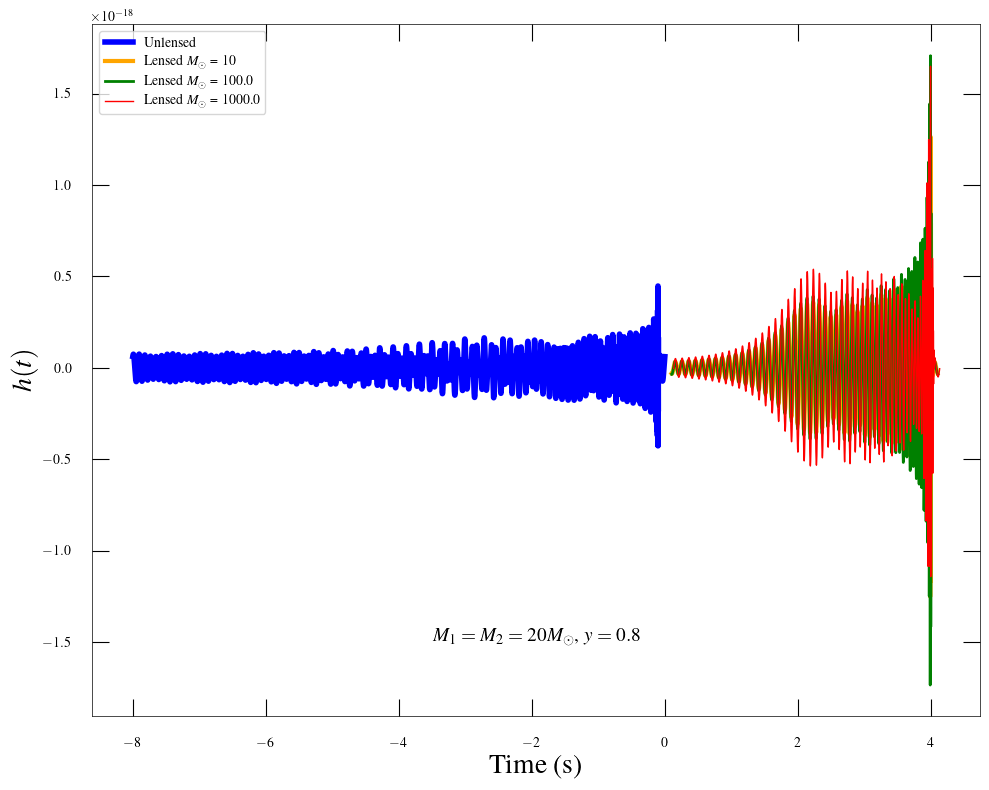

In [11]:
num_curves = len(Mlz)
linewidths = np.linspace(3, 1, num_curves)

plt.figure(figsize=(10, 8))

plt.plot(hp_ts.sample_times, hp_ts.cyclic_time_shift(-0.1), label='Unlensed', color='blue', linewidth=4)

for i in range(num_curves):
    plt.plot(hp_lensed_ts[i].sample_times, hp_lensed_ts[i],
               label=fr'Lensed $M_\odot$ = {Mlz[i]}',
               color=color[i],
               linewidth=linewidths[i])


plt.xlabel(r"Time (s)")
plt.ylabel(r'$h(t)$')
# plt.xlim(10, 1024)
# plt.ylim(1e-28, 1e-19)
plt.legend()

ax = plt.gca()
ax.text(-3.5, -1.5e-18, rf'$M_1 = M_2 = {mass1} M_\odot$, $y = 0.8$', fontsize=14)

set_tick_sizes(ax, major=12, minor=7)

plt.tight_layout()
plt.savefig('FD_lensed_waveform.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [12]:
for i in range(num_curves):
    print(hp_lensed_ts[i].end_time)

4.100323456
4.103234563
4.132345633


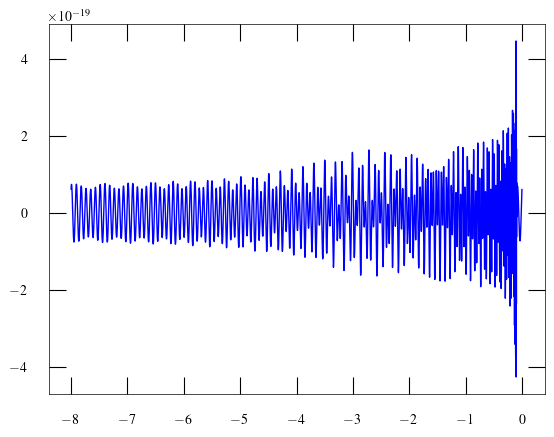

In [13]:
# plt.plot(hp_lensed_ts[i].sample_times, hp_lensed_ts[i],
#                label=fr'Lensed $M_\odot$ = {Mlz[i]}',
#                color=color[i],
#                linewidth=linewidths[i])

plt.plot(hp_ts.sample_times, hp_ts.cyclic_time_shift(-0.1), label='Unlensed', color='blue', linewidth=1)